# Fase Modello
Obiettivo: stimare quanto hanno pesato le crisi sui prezzi del carrello,
al netto di materie prime, energia e cambio.

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

PROCESSED = Path("../data_market/processed")
dataset = pd.read_csv(PROCESSED / "dataset_mensile.csv", index_col="data", parse_dates=True)

def var12(serie):
    return serie.pct_change(12, fill_method=None) * 100

def in_euro(serie):
    return serie / dataset["eur_usd"]

## 5a – Regressione: pasta e grano

### L'idea
Una **regressione lineare** cerca la retta che descrive meglio il legame tra due variabili.
Ogni punto è un mese: in orizzontale la variazione su 12 mesi del grano (7 mesi prima,
il ritardo trovato nella Fase 4), in verticale la variazione su 12 mesi della pasta.

$$\text{var. pasta} = a + b \times \text{var. grano (7 mesi prima)}$$

- **b** (coefficiente del grano): di quanto sale la pasta, 7 mesi dopo, per ogni 1% di
  aumento del grano. Esempio: con b = 0,2, un aumento del grano del 50% porta a un
  aumento della pasta del 10%. Ci si aspetta b minore di 1, perché il grano è solo una
  parte del costo della pasta (insieme a energia, trasporto, imballaggio, distribuzione).
- **a** (intercetta): la variazione della pasta quando il grano è fermo, cioè la parte di
  aumento che non dipende dal grano (salari, costi generali, inflazione "normale").

### Come leggere i risultati
- **coef**: il valore di b
- **p-value** (`P>|t|`): la probabilità di trovare un legame così forte anche se in realtà
  non esistesse. Sotto 0,05 il legame si considera statisticamente significativo.
- **R²** (`R-squared`): la quota delle variazioni della pasta spiegata dal grano
  (0,6 = 60%). Il resto dipende da altri fattori.

### Limite di questo primo modello
Con una sola variabile, il modello attribuisce al grano anche l'effetto di fattori che si
muovono insieme a lui, come l'energia. Nei passi successivi si aggiungono altre variabili:
ogni coefficiente misurerà l'effetto di un fattore **tenendo fermi gli altri**.

In [77]:
df = pd.DataFrame({
    "pasta": var12(dataset["pasta"]),
    "grano_lag7": var12(in_euro(dataset["grano"])).shift(7),
}).dropna()

modello = smf.ols("pasta ~ grano_lag7", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(modello.summary())

                            OLS Regression Results                            
Dep. Variable:                  pasta   R-squared:                       0.680
Model:                            OLS   Adj. R-squared:                  0.677
Method:                 Least Squares   F-statistic:                     41.53
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.47e-09
Time:                        15:00:37   Log-Likelihood:                -333.49
No. Observations:                 123   AIC:                             671.0
Df Residuals:                     121   BIC:                             676.6
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9024      0.743      2.559      0.0

In [78]:
#Trova il ritardo del gas
v_pasta = var12(dataset["pasta"])
v_gas = var12(in_euro(dataset["gas_europa"]))
corr_gas = pd.Series({l: v_pasta.corr(v_gas.shift(l)) for l in range(19)})
print("Ritardo migliore del gas:", corr_gas.idxmax(), "mesi – corr:", round(corr_gas.max(), 2))

Ritardo migliore del gas: 11 mesi – corr: 0.91


## 5a – Regressione con controlli: grano, energia e guerra

Il primo modello attribuisce al grano tutto il merito dei movimenti della pasta.
Ma grano ed energia sono saliti insieme nel 2021–2022: per separare i due effetti
il modello include più variabili insieme.

$$\text{var. pasta} = a + b \cdot \text{grano}_{t-7} + c \cdot \text{gas}_{t-11} + d \cdot \text{ucraina}$$

| Variabile | Cosa misura | Perché |
|---|---|---|
| `grano_lag7` | variazione su 12 mesi del grano in euro, 7 mesi prima | materia prima principale (ritardo dalla Fase 4) |
| `gas_lag` | variazione su 12 mesi del gas europeo in euro, 11 mesi prima | costo dell'energia (macinatura, essiccazione, trasporto) |
| `ucraina` | **dummy**: 1 nei 12 mesi dopo l'invasione (mar 2022 – feb 2023), 0 altrove | effetto della guerra non spiegato da grano ed energia |

Ogni coefficiente misura l'effetto di una variabile **tenendo fermi gli altri**.
Il coefficiente di `ucraina` risponde alla domanda: nell'anno dopo l'invasione, la pasta
è salita più di quanto spiegano grano ed energia?

Il cambio euro/dollaro non è incluso come variabile separata: grano e gas sono già
convertiti in euro, quindi il suo effetto è già compreso.

Il ritardo del gas (11 mesi) è scelto come quello con la correlazione più alta con la pasta
(0,91), come per il grano nella Fase 4.

**Errori standard HAC (Newey-West).** Le variazioni su 12 mesi di mesi vicini si
sovrappongono, quindi gli errori del modello sono legati tra loro (Durbin-Watson del primo
modello: 0,33, lontano dal valore ideale di 2). Questo non cambia i coefficienti, ma rende
il modello troppo sicuro di sé. Gli errori standard HAC correggono il problema: gli
intervalli di confidenza diventano più larghi e più onesti.

In [79]:
LAG_GAS = 11

df = pd.DataFrame({
    "pasta": v_pasta,
    "grano_lag7": var12(in_euro(dataset["grano"])).shift(7),
    "gas_lag": v_gas.shift(LAG_GAS),
})
df["ucraina"] = ((df.index >= "2022-03-01") & (df.index <= "2023-02-01")).astype(int)
df = df.dropna()

modello2 = smf.ols("pasta ~ grano_lag7 + gas_lag + ucraina", data=df).fit(
    cov_type="HAC", cov_kwds={"maxlags": 12})
print(modello2.summary())

                            OLS Regression Results                            
Dep. Variable:                  pasta   R-squared:                       0.881
Model:                            OLS   Adj. R-squared:                  0.878
Method:                 Least Squares   F-statistic:                     570.8
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           7.14e-69
Time:                        15:00:37   Log-Likelihood:                -264.93
No. Observations:                 119   AIC:                             537.9
Df Residuals:                     115   BIC:                             549.0
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9844      0.433      2.274      0.0

### Risultati

| | Modello 1 (solo grano) | Modello 2 (grano + gas + guerra) |
|---|---|---|
| Coefficiente del grano | 0,196 | **0,078** |
| Coefficiente del gas | – | **0,022** |
| Coefficiente di `ucraina` | – | 2,73 (p = 0,117) |
| R² | 0,68 | **0,88** |

**1. Il modello spiega molto di più.** Con grano, energia e guerra l'R² passa dal 68%
all'88%.

**2. Il grano "perde merito".** Tenendo fermo il gas, il suo coefficiente scende da 0,196
a 0,078: nel primo modello il grano si prendeva anche l'effetto dell'energia, che saliva
insieme a lui. È l'effetto di una variabile confondente. L'effetto del grano resta comunque
significativo (p < 0,001).

**3. L'energia pesa quanto il grano.** Il coefficiente del gas sembra piccolo (0,022),
ma il gas si è mosso moltissimo: a un aumento del 300% corrispondono circa 6,7 punti
di aumento della pasta.

**4. Nessun effetto "extra" chiaro della guerra.** Il coefficiente di `ucraina` (2,7 punti)
non è statisticamente significativo: p = 0,117 e intervallo di confidenza da −0,7 a +6,1,
che comprende lo zero. **Non emerge un effetto aggiuntivo significativo**: la guerra
sembra aver pesato sulla pasta soprattutto attraverso grano ed energia, in linea con la
Fase 4. Attenzione: non significativo non vuol dire zero; con 12 mesi di dati il modello
ha poca informazione per misurare un piccolo effetto aggiuntivo.

**Note tecniche.**
- Il Durbin-Watson sale da 0,33 a 0,71: aggiungendo il gas, una parte degli errori
  sistematici viene spiegata. Gli errori standard HAC tengono conto di quella che resta.
- L'avviso sul *condition number* (1.040) segnala una possibile multicollinearità tra
  grano e gas, dovuta in parte anche alle scale diverse delle variabili. Gli intervalli
  di confidenza di grano e gas restano stretti: il modello riesce a separare i due effetti.

In [80]:
p = modello2.params      # i coefficienti del modello

contributi = pd.DataFrame({
    "Base (inflazione normale)": p["Intercept"], #l'intercetta ci da l'inflazione
    "Grano": p["grano_lag7"] * df["grano_lag7"], #operazione vettorizzata--> p è un valore e df è una colonna con le variazioni (cofficiente x variabile)
    "Energia (gas)": p["gas_lag"] * df["gas_lag"], #
    "Guerra (extra)": p["ucraina"] * df["ucraina"],
}, index=df.index)
contributi["Non spiegato"] = df["pasta"] - modello2.fittedvalues #vera variazione della pasta - variazione prevista dal modello (grano+energia+guerra)= residuo

# Controllo: la somma dei pezzi deve dare la variazione vera della pasta
print("Differenza massima:", (contributi.sum(axis=1) - df["pasta"]).abs().max().round(6))

Differenza massima: 0.0


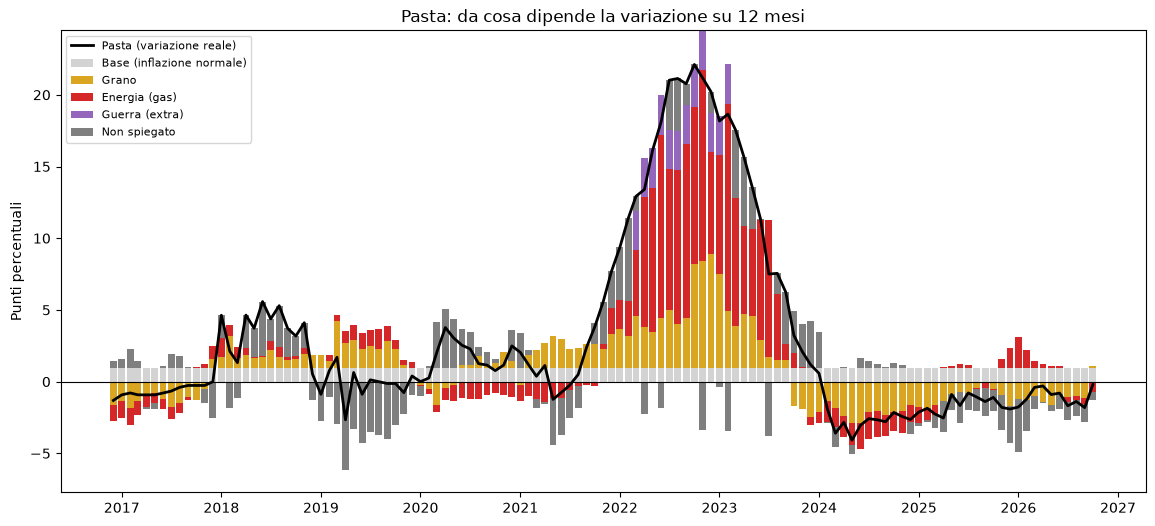

In [81]:
colori = ["lightgray", "goldenrod", "tab:red", "tab:purple", "tab:gray"]

fig, ax = plt.subplots(figsize=(14, 6))
base_pos = pd.Series(0.0, index=contributi.index)
base_neg = pd.Series(0.0, index=contributi.index)

for col, colore in zip(contributi.columns, colori):
    pos = contributi[col].clip(lower=0)
    neg = contributi[col].clip(upper=0)
    ax.bar(contributi.index, pos, bottom=base_pos, width=25, color=colore, label=col)
    ax.bar(contributi.index, neg, bottom=base_neg, width=25, color=colore)
    base_pos += pos
    base_neg += neg

ax.plot(df.index, df["pasta"], color="black", linewidth=2, label="Pasta (variazione reale)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Pasta: da cosa dipende la variazione su 12 mesi")
ax.set_ylabel("Punti percentuali")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### Scomposizione della variazione della pasta

Ogni barra mostra da cosa è composta la variazione su 12 mesi della pasta in quel mese:
**contributo = coefficiente del modello × valore della variabile**.
La parte "non spiegato" (residuo) è la differenza tra la variazione vera e quella prevista
dal modello; la somma di tutte le parti ricostruisce esattamente la variazione vera
(linea nera). Quando il residuo è negativo, la cima delle barre positive supera la linea.

**Osservazioni.**
- **Nel picco 2022–2023 domina l'energia**: il contributo del gas è più grande di quello
  del grano. Per la pasta il costo dell'energia ha pesato più della materia prima.
- **Il contributo extra della guerra è piccolo** e in alcuni mesi è "compensato" da un
  residuo negativo: il modello prevede più aumento di quello avvenuto.
  È coerente con il coefficiente di `ucraina` non significativo.
- **Nel 2016–2019 il residuo è grande**: movimenti della pasta che grano tenero ed energia
  non spiegano. Ipotesi: il ruolo del grano duro, non disponibile nei dati.

In [ ]:
# Crisi da testare: nome -> (primo mese, ultimo mese)
CRISI = {
    "ucraina":   ("2022-03-01", "2023-02-01"),
}

CONTROLLI = {
    "gas": "gas_europa",
    "trasporti": "brent",
    "fertilizzanti": "urea",
}


def miglior_lag(y, x, lag_max=18):
    """Il ritardo di x (in mesi) con la correlazione più alta con y."""
    corr = pd.Series({l: y.corr(x.shift(l)) for l in range(lag_max + 1)})
    return corr.idxmax()

def modello_prodotto(prodotto, materia, controlli=CONTROLLI):
    """Regressione: prodotto ~ materia prima (lungo e breve) + controlli + crisi (errori HAC)."""
    y = var12(dataset[prodotto])
    x_materia = var12(in_euro(dataset[materia]))
    lags = {"materia": miglior_lag(y, x_materia)}

    df = pd.DataFrame({
        "y": y,
        "materia": x_materia.shift(lags["materia"]),
        "materia_breve": x_materia.shift(1),
    })
    for nome, colonna in controlli.items():          # un ritardo "migliore" per ogni controllo
        x = var12(in_euro(dataset[colonna]))
        lags[nome] = miglior_lag(y, x)
        df[nome] = x.shift(lags[nome])

    for nome, (inizio, fine) in CRISI.items():
        df[nome] = ((df.index >= inizio) & (df.index <= fine)).astype(int)
    df = df.dropna()

    variabili = [c for c in df.columns if c != "y"]
    formula = "y ~ " + " + ".join(variabili)
    mod = smf.ols(formula, data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    return mod, df, lags

In [83]:
CONFRONTI = {
    "pane": "grano", "pasta": "grano", "olio_girasole": "girasole_mondo",
    "caffe": "caffe_robusta", "zucchero": "zucchero_mondo", "latte": "fao_latticini",
}

righe, modelli = [], {}
for prodotto, materia in CONFRONTI.items():
    mod, df_p, lag_m, lag_g = modello_prodotto(prodotto, materia)
    modelli[prodotto] = (mod, df_p)
    riga = {
        "prodotto": prodotto,
        "lag_materia": lag_m, "coef_materia": mod.params["materia"], "p_materia": mod.pvalues["materia"],
        "coef_breve": mod.params["materia_breve"], "p_breve": mod.pvalues["materia_breve"],
        "lag_gas": lag_g, "coef_gas": mod.params["gas"], "p_gas": mod.pvalues["gas"],
    }
    for nome in CRISI:
        riga[f"coef_{nome}"] = mod.params[nome]
        riga[f"p_{nome}"] = mod.pvalues[nome]
    riga["R2"] = mod.rsquared
    righe.append(riga)

riepilogo = pd.DataFrame(righe).set_index("prodotto").round(3)
riepilogo

,lag_materia,coef_materia,p_materia,coef_breve,p_breve,lag_gas,coef_gas,p_gas,coef_ucraina,p_ucraina,R2
prodotto,,,,,,,,,,,
pane,10,0.023,0.237,-0.026,0.025,13,0.017,0.000,4.886,0.000,0.925
pasta,7,0.074,0.001,0.008,0.528,11,0.023,0.000,2.304,0.122,0.882
olio_girasole,8,0.106,0.035,0.154,0.000,6,0.028,0.003,36.251,0.000,0.914
caffe,11,0.201,0.000,0.031,0.107,11,-0.005,0.198,-1.926,0.037,0.756
zucchero,15,0.063,0.053,0.077,0.022,16,0.079,0.000,2.609,0.483,0.810
latte,8,0.073,0.038,0.010,0.690,13,0.021,0.000,0.603,0.664,0.853


### Modello con ritardo breve della materia prima

Ai modelli è stata aggiunta la materia prima con ritardo di 1 mese (`materia_breve`),
oltre al ritardo "migliore", per cogliere anche la reazione immediata.

| Prodotto | Mat. prima (lungo) | Mat. prima (1 mese) | Gas | Extra guerra | R² |
|---|---|---|---|---|---|
| Pane | n.s. | ✅ (negativo) | ✅ | ✅ **+4,9** | 0,93 |
| Pasta | ✅ | n.s. | ✅ | n.s. (+2,3) | 0,88 |
| Olio di girasole | ✅ | ✅ | ✅ | ✅ **+36,3** | 0,91 |
| Caffè | ✅ | n.s. | n.s. | ✅ **−1,9** | 0,76 |
| Zucchero | n.s. (p = 0,053) | ✅ | ✅ | n.s. (+2,6) | 0,81 |
| Latte | ✅ | n.s. | ✅ | n.s. (+0,6) | 0,85 |

(✅ = p < 0,05; n.s. = non significativo)

**Il ritardo breve non spiega l'extra del girasole.** È significativo e migliora il modello
(R² da 0,87 a 0,91), ma l'effetto aggiuntivo della guerra resta di circa 36 punti:
l'ipotesi che dipendesse solo dal ritardo è smentita.

**L'effetto extra della guerra non riguarda tutti i prodotti.** È grande per l'olio di
girasole, moderato per il pane, assente per pasta, zucchero e latte. Per il caffè è
negativo: nel 2022 è salito meno di quanto prevedono materia prima ed energia.

**Cosa misura la dummy.** Non una causa precisa, ma tutto ciò che nell'anno dopo
l'invasione non è spiegato da materia prima ed energia. Possibili componenti:
scarsità fisica del prodotto (girasole importato dall'Ucraina, porti bloccati),
acquisti di scorte nella primavera 2022, trasmissione più forte durante gli shock grandi
(il modello lineare assume un legame sempre uguale), costi non inclusi (trasporti,
fertilizzanti, elettricità, imballaggi), eventuali margini più alti.

**Cautele.**
- Il coefficiente negativo del ritardo breve nel pane è difficile da interpretare:
  probabilmente è dovuto a variabili molto legate tra loro, non a un effetto reale.
- Con 6 prodotti testati, un risultato significativo può comparire anche per caso
  (al 5% ci si aspetta circa un "falso positivo" ogni 20 test): il valore negativo
  del caffè va preso con prudenza.

**Prossimo passo:** aggiungere trasporti (Brent come approssimazione del gasolio)
e fertilizzanti (urea) per verificare se l'effetto extra della guerra si riduce.